Data source: US Bureau of Transportation Statistics (BTS), Airline On-Time Performance. The source contains individual flight records.

Before running: Put the file On_Time_Fights_Aug.csv in the same folder as this notebook.

In [95]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import warnings
from scipy.stats import randint, norm, binom, poisson


warnings.filterwarnings('ignore')
file = "On_Time_Fights_Aug.csv"

We keep

In [3]:
columns = [
 'Year','Month','FlightDate','DayOfWeek','Reporting_Airline',
 'Flight_Number_Reporting_Airline','Origin','Dest',
 'DepDelay','ArrDelay','ArrDel15','TaxiOut','AirTime','Distance',
 'Cancelled','Diverted','CancellationCode','CarrierDelay','WeatherDelay',
 'NASDelay','SecurityDelay','LateAircraftDelay',
]

In [6]:
df_cat = pd.read_csv(file, usecols=['Reporting_Airline', 'Origin', 'Dest', 'CancellationCode', 'Flight_Number_Reporting_Airline'])
df_cat.head()


,Reporting_Airline,Flight_Number_Reporting_Airline,Origin,Dest,CancellationCode
0,DL,1209,PDX,SLC,NaN
1,DL,1209,SLC,PDX,NaN
2,DL,1209,PDX,SLC,NaN
3,DL,1209,SLC,PDX,NaN
4,DL,1209,PDX,SLC,NaN


In [11]:
print("Missing values:")
print(df_cat.isna().sum().head(11))
print("Top origin airports:")
print(df_cat["Origin"].value_counts().head(10))

Missing values:
Reporting_Airline                       0
Flight_Number_Reporting_Airline         0
Origin                                  0
Dest                                    0
CancellationCode                   597076
dtype: int64
Top origin airports:
Origin
ORD    33187
DEN    28557
DFW    27347
ATL    27221
LAX    16494
SEA    15908
CLT    15125
PHX    14757
LAS    13832
SFO    13560
Name: count, dtype: int64


In [7]:
df_quant = pd.read_csv(file, usecols=['DepDelay', 'ArrDelay', 'TaxiOut', 'AirTime', 'Distance', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay'])
df_quant.head()

,DepDelay,TaxiOut,ArrDelay,AirTime,Distance,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,-1.0,18.0,4.0,90.0,630.0,NaN,NaN,NaN,NaN,NaN
1,-4.0,16.0,-12.0,87.0,630.0,NaN,NaN,NaN,NaN,NaN
2,42.0,14.0,34.0,85.0,630.0,0.0,0.0,0.0,0.0,34.0
3,41.0,14.0,47.0,103.0,630.0,0.0,0.0,6.0,0.0,41.0
4,-8.0,15.0,-6.0,89.0,630.0,NaN,NaN,NaN,NaN,NaN


In [9]:
print("Missing values:")
print(df_quant.isna().sum().head(11))

Missing values:
DepDelay              10655
TaxiOut               11260
ArrDelay              14182
AirTime               14182
Distance                  0
CarrierDelay         448753
WeatherDelay         448753
NASDelay             448753
SecurityDelay        448753
LateAircraftDelay    448753
dtype: int64


In [21]:
df = pd.read_csv(file, usecols=[
    "FlightDate", "Month", "Reporting_Airline", "Origin", "Dest",
    "DepDelay", "ArrDelay", "ArrDel15", "Distance", "AirTime", "Cancelled", "DayOfWeek"
])

In [24]:
days = {
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday",
    7: "Sunday"
}

df["DayOfWeek"] = df["DayOfWeek"].map(days)

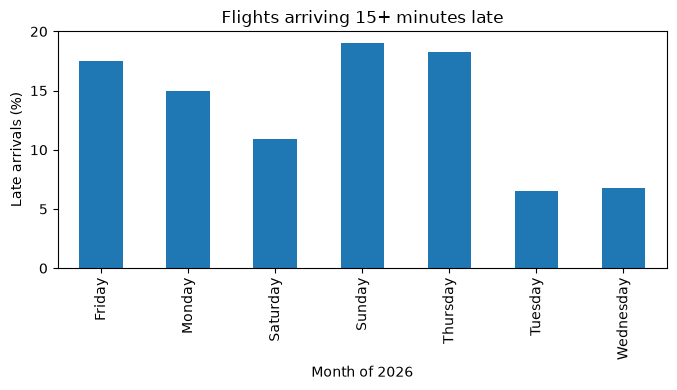

In [25]:
valid = df[df["ArrDel15"].isin([0, 1])]
late_pct = valid.groupby("DayOfWeek")['ArrDelay'].mean()

late_pct.plot(kind="bar", figsize=(7, 4))
plt.title("Flights arriving 15+ minutes late")
plt.xlabel("Days of the week")
plt.ylabel("Late arrivals (%)")
plt.tight_layout()
plt.show()

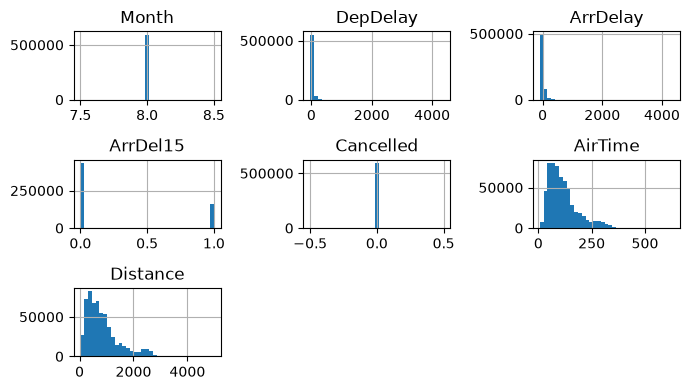

In [30]:
arrival = df['ArrDelay'].dropna()
arrival_plot = df[df["ArrDel15"].between(-30, 180)]
arrival_plot.hist(bins=35, figsize=(7,4))
plt.title("Arrival delay distribuition between -30 to 180 min")
plt.xlabel("Arrival delay per minutes")
plt.ylabel("Number of flights")
plt.tight_layout()
plt.show()

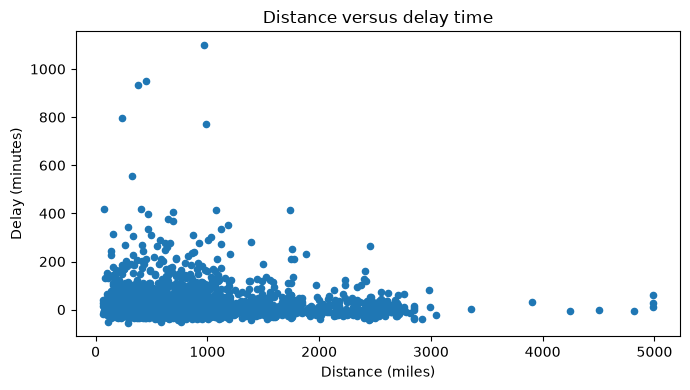

In [42]:
distancePerDelay = df[["Distance", "ArrDelay"]].dropna().sample(3000, random_state =42)
distancePerDelay.plot.scatter(x="Distance", y="ArrDelay",figsize=(7, 4))
plt.title("Distance versus delay time")
plt.xlabel("Distance (miles)")
plt.ylabel("Delay (minutes)")
plt.tight_layout()
plt.show()

#Binomial Distribution
If we select 100 flights, how many will be late at least 15 minutes?
X Binomial(n=100,p), E(X)=np, Var(X)=np(1-p)
The graph compares the binomial probabilities with a normal approximation as an illustration of what happens when n is large enough for np and n(1-p) to be reasonably large.

n - Flights quantity.
p - Probability.
E(x) - Expected delayed flights.
Var(x) - Variance of this number.

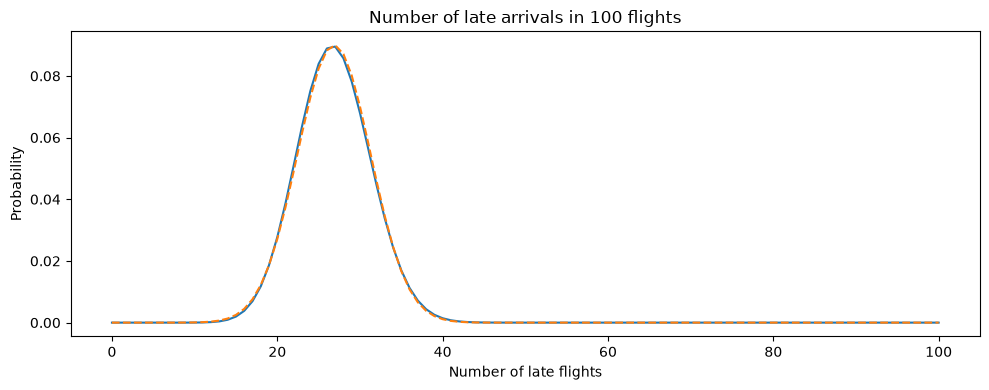

In [94]:
p = valid["ArrDel15"].mean()
n = 100
x = np.arange(0, n + 1) # possible outcomes (0–n+1)

plt.figure(figsize=(10,4))
plt.plot(x, binom.pmf(x, n, p), label="Binomial")
plt.plot(x, norm.pdf(x, n * p, np.sqrt(n * p * (1-p))),
         label="Normal approximation", linestyle="--")
#
plt.title("Number of late arrivals in 100 flights")
plt.xlabel("Number of late flights")
plt.ylabel("Probability")
plt.tight_layout()
plt.show()

### **Poisson Distribution**

**Definition**:  
The **Poisson Distribution** describes the number of events that occur in a fixed interval of time or space when these events happen with a known constant mean rate (\( \lambda \)) and are independent of the time since the last event.



#### **Formula**:
The probability of observing \( k \) events in a given interval is given by the Poisson probability mass function (PMF):

$$
P(X = k) = \frac{e^{-\lambda} \lambda^k}{k!}
$$

Where:
- \( \lambda \) = average number of events in the interval
- \( k \) = number of events
- \( e \) = Euler's number (approximately 2.71828)


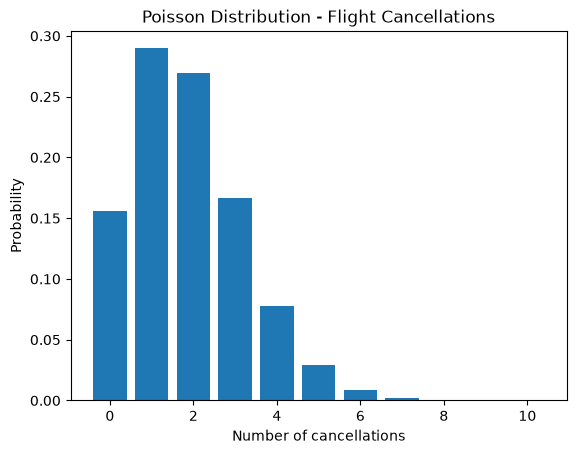

In [144]:

# Probability of cancellation
p = df["Cancelled"].mean()

# Expected cancellations per 100 flights
lambda_value = 100 * p

# Possible number of cancellations
x = np.arange(0, 11)

# Poisson distribution
plt.bar(x, poisson.pmf(x, lambda_value))
plt.xlabel("Number of cancellations")
plt.ylabel("Probability")
plt.title("Poisson Distribution - Flight Cancellations")
plt.show()

Mean: 115.70405767687018
Standard deviation: 70.95826327891176


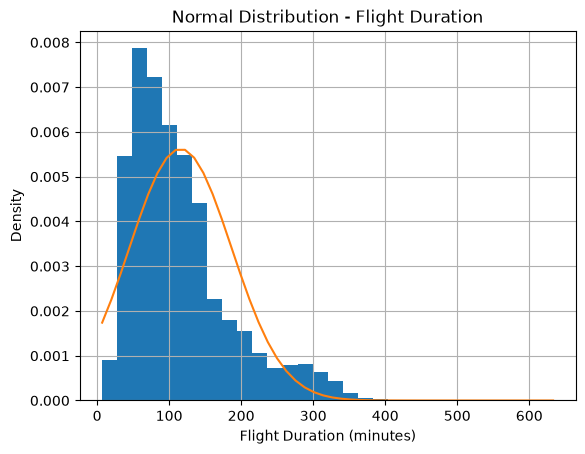

In [160]:
# print("Airport origin:", df['Origin'])
# print("Airport dest:", df['Dest'])
# Select one route
flights = df.query("Origin == 'JFK' and Dest == 'LAX'")
# Flight duration
time = df["AirTime"].dropna()

# Mean and standard deviation
mu = time.mean()
sd = time.std()

print("Mean:", mu)
print("Standard deviation:", sd)

# Plot histogram
time.hist(bins=30, density=True)

# Normal distribution
x = np.linspace(time.min(), time.max())
plt.plot(x, norm.pdf(x, mu, sd))

plt.title("Normal Distribution - Flight Duration")
plt.xlabel("Flight Duration (minutes)")
plt.ylabel("Density")
plt.show()